# A3-A4 orbit cleaning checks

This notebook documents the cohort's raw-versus-cleaned TLE points, the tighter cleaning diagnostic, and the May 2024 storm-onset interval check. It uses the ignored data outputs made by the A3-A4 pipeline.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = Path.home() / 'Documents' / 'icarus-storm-decay'
sys.path.insert(0, str(ROOT))
from src.orbit import clean_tle_history, tles_to_frame
from src.storms import load_storms

RAW = ROOT / 'data' / 'raw'
PROCESSED = ROOT / 'data' / 'processed'
RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)

records = []
for path in sorted(RAW.glob('tle_a3a4_chunk_*.json')):
    records.extend(json.loads(path.read_text()))
raw_tles = tles_to_frame(records)
baseline, _ = clean_tle_history(raw_tles)
tight, tight_report = clean_tle_history(
    raw_tles, max_inc_jump_deg=0.25,
    max_raan_rate_residual_deg_per_day=0.5,
    rolling_mad_threshold=5.0, outlier_floor_km=0.25,
)
intervals = pd.read_parquet(PROCESSED / 'orbit_intervals_a3a4.parquet')
storms = load_storms(PROCESSED / 'storms.parquet')
tight_report

,step,count
0,input TLEs,237782
1,duplicate epochs removed,33828
2,inclination jumps flagged,0
3,RAAN jumps flagged,0
4,rolling-median outliers flagged,15
5,TLEs failed point-level checks,15
6,TLEs retained by point-level checks,203939


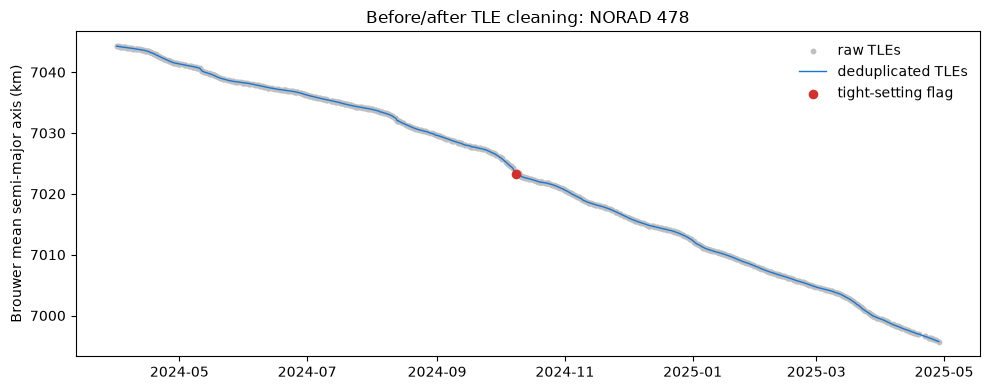

In [2]:
# Pick a real object with a tighter-setting flag; fall back to the densest history.
flagged_ids = tight.loc[tight.tle_ok.eq(0), 'norad_id']
norad_id = int(flagged_ids.iloc[0]) if len(flagged_ids) else int(baseline.norad_id.value_counts().index[0])
raw_one = raw_tles[raw_tles.norad_id.eq(norad_id)].sort_values('epoch')
base_one = baseline[baseline.norad_id.eq(norad_id)].sort_values('epoch')
tight_one = tight[tight.norad_id.eq(norad_id)].sort_values('epoch')

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(raw_one.epoch, raw_one.a_km, s=10, color='0.75', label='raw TLEs')
ax.plot(base_one.epoch, base_one.a_km, lw=1, color='#1976d2', label='deduplicated TLEs')
flagged = tight_one[tight_one.tle_ok.eq(0)]
if len(flagged):
    ax.scatter(flagged.epoch, flagged.a_km, s=35, color='#d32f2f', label='tight-setting flag', zorder=3)
ax.set(title=f'Before/after TLE cleaning: NORAD {norad_id}', ylabel='Brouwer mean semi-major axis (km)')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / 'a3a4_cleaning_before_after.png', dpi=160)
plt.show()

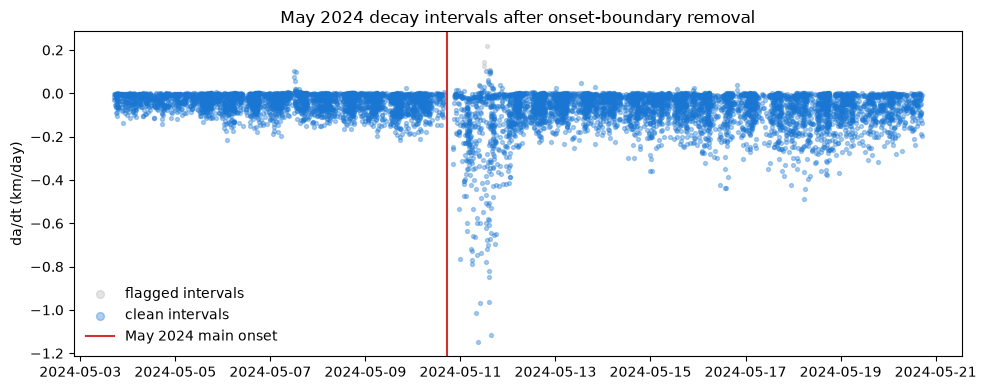

,intervals,objects
tle_ok,,
0,6,6
1,8426,265


In [3]:
may_onset = storms.loc[storms.main_onset.eq(pd.Timestamp('2024-05-10 17:00')), 'main_onset'].iloc[0]
may = intervals.loc[intervals.t_mid.between(may_onset - pd.Timedelta(days=7), may_onset + pd.Timedelta(days=10))].copy()
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(may.loc[may.tle_ok.eq(0), 't_mid'], may.loc[may.tle_ok.eq(0), 'da_dt_km_per_day'],
           s=8, alpha=0.35, color='0.7', label='flagged intervals')
ax.scatter(may.loc[may.tle_ok.eq(1), 't_mid'], may.loc[may.tle_ok.eq(1), 'da_dt_km_per_day'],
           s=8, alpha=0.35, color='#1976d2', label='clean intervals')
ax.axvline(may_onset, color='#d32f2f', lw=1.5, label='May 2024 main onset')
ax.set(title='May 2024 decay intervals after onset-boundary removal', ylabel='da/dt (km/day)')
ax.legend(frameon=False, markerscale=2)
fig.tight_layout()
fig.savefig(RESULTS / 'a3a4_may2024_intervals.png', dpi=160)
plt.show()

assert not ((may.t_start < may_onset) & (may.t_end > may_onset)).any()
assert may.dt_days.le(5).all()
may.groupby('tle_ok').agg(intervals=('norad_id', 'size'), objects=('norad_id', 'nunique'))